# Notebook 06: RetailMart 360 — Strategic Business Insights & Executive Synthesis

**Project:** RetailMart 360 — Retail Sales & Customer Intelligence  
**Role:** Senior Data Analyst & Analytics Consultant  
**Environment:** Python 3.13 | Pandas | Matplotlib | Business Advisory  

---

## 1. Executive Synthesis & Strategic Questions
This capstone notebook synthesizes analytical findings across Sales EDA, RFM Customer Intelligence, Product Profitability, Geographic Market Penetration, Sales Team Productivity, and Cash Collections.

### Core Strategic Questions Addressed:
1. What are the primary commercial drivers of RetailMart's $8.87M in realized revenue?
2. Which sovereign markets and sales offices represent the company's core economic engine?
3. How effectively are sales representatives distributed across accounts and geographic territories?
4. What cash collection patterns and customer balance exposure exist?
5. What are the top 10 prioritized, data-backed business recommendations for executive leadership?


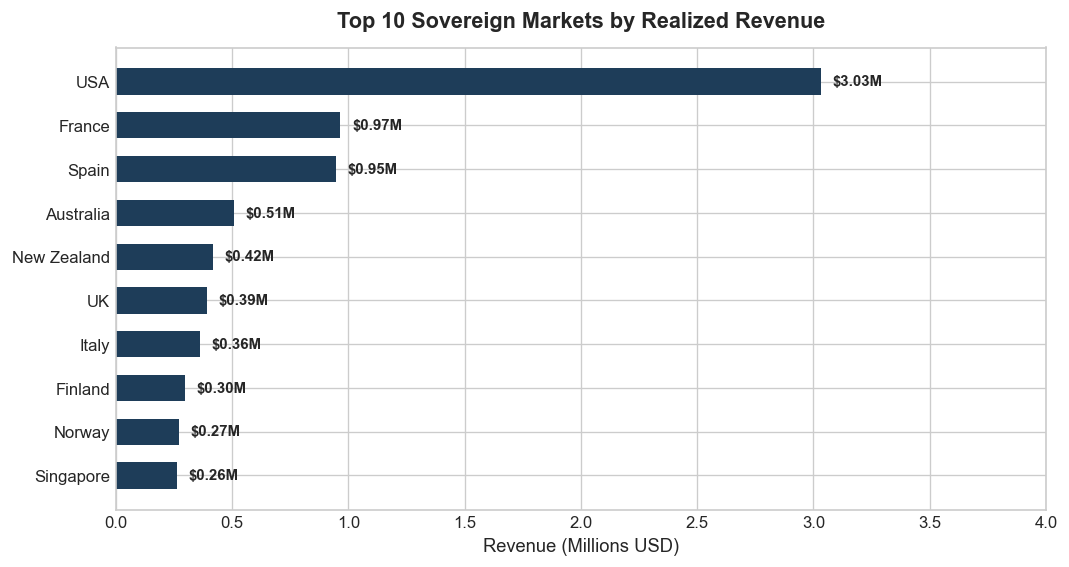

In [1]:
# Geographic Sovereign Market Performance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

mart = pd.read_csv("../data/processed/sales_analytical_mart.csv")
shipped = mart[mart["is_shipped"]].copy()

geo = shipped.groupby("customerCountry").agg(
    revenue=("revenue", "sum"),
    orders=("orderNumber", "nunique"),
    customers=("customerNumber", "nunique")
).reset_index().sort_values("revenue", ascending=False)
geo["revenue_share_pct"] = (geo["revenue"] / geo["revenue"].sum() * 100).round(2)
display(geo.head(10))

# Plot top markets
top_geo = geo.head(10).sort_values("revenue", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top_geo["customerCountry"], top_geo["revenue"] / 1e6, color='#1e3d59', height=0.6)
ax.set_title("Top 10 Sovereign Markets by Realized Revenue", fontsize=13, fontweight='bold')
ax.set_xlabel("Revenue (Millions USD)")
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"${w:.2f}M", va='center', fontsize=9, fontweight='bold')
ax.set_xlim(0, 4.0)
plt.tight_layout()
plt.show()


## 2. Sales Representative Performance & Workload Equity
We examine the 15 commissioned sales representatives to assess revenue attribution, managed accounts, and deal sizes.


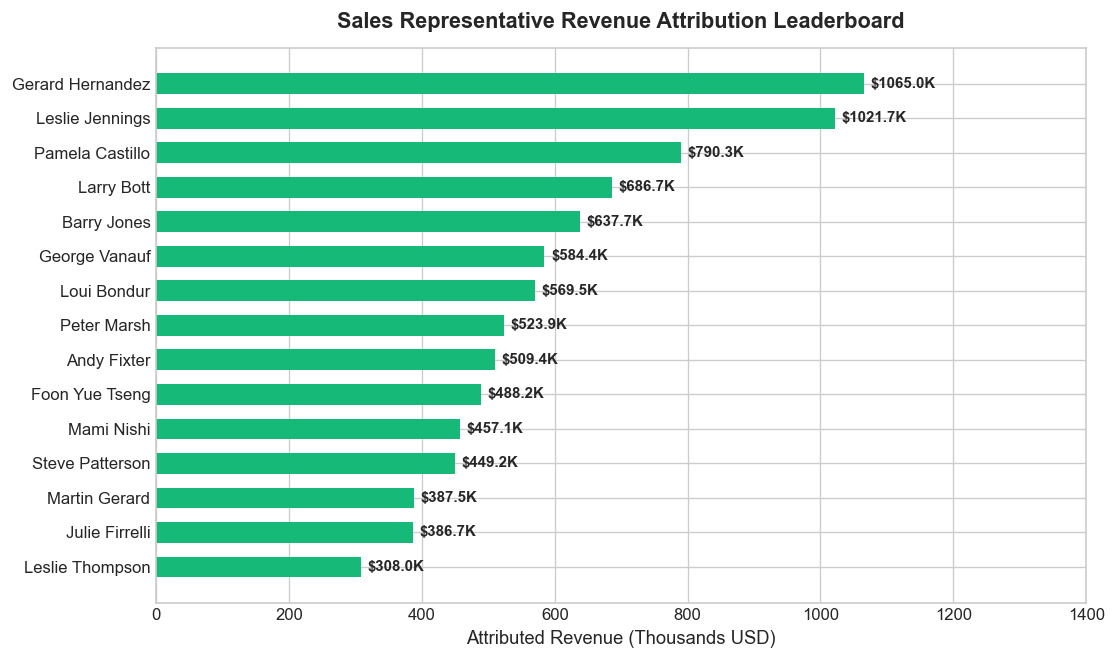

In [2]:
# Sales Rep Leaderboard Plot
rep = shipped.groupby(["salesRepName", "officeCity"]).agg(
    revenue=("revenue", "sum"),
    orders=("orderNumber", "nunique"),
    customers=("customerNumber", "nunique")
).reset_index().sort_values("revenue", ascending=False)
rep["revenue_share_pct"] = (rep["revenue"] / rep["revenue"].sum() * 100).round(2)
display(rep)

top_reps = rep.sort_values("revenue", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_reps["salesRepName"], top_reps["revenue"] / 1e3, color='#17b978', height=0.6)
ax.set_title("Sales Representative Revenue Attribution Leaderboard", fontsize=13, fontweight='bold')
ax.set_xlabel("Attributed Revenue (Thousands USD)")
for bar in bars:
    w = bar.get_width()
    ax.text(w + 10, bar.get_y() + bar.get_height()/2, f"${w:.1f}K", va='center', fontsize=9, fontweight='bold')
ax.set_xlim(0, 1400)
plt.tight_layout()
plt.show()


## 3. Account-Level Cash Reconciliation Proxy
By comparing cumulative shipped order value against cash collections at the customer grain, we evaluate net account exposure.


In [3]:
from src.analytics import get_customer_balance_proxy
orders_c = pd.read_csv("../data/processed/orders_clean.csv")
orderdetails_c = pd.read_csv("../data/processed/orderdetails_clean.csv")
payments_c = pd.read_csv("../data/processed/payments_clean.csv")
customers_c = pd.read_csv("../data/processed/customers_clean.csv")

balance_proxy = get_customer_balance_proxy(orders_c, orderdetails_c, payments_c, customers_c)
print("Top 10 Accounts by Net Outstanding Order Value Proxy:")
display(balance_proxy.head(10)[["customerNumber", "customerName", "country", "creditLimit", "totalShippedOrderValue", "totalPaymentsCollected", "netOutstandingProxy", "paymentCoverageRatio"]])


Top 10 Accounts by Net Outstanding Order Value Proxy:
   customerNumber                  customerName      country  creditLimit  totalShippedOrderValue  totalPaymentsCollected  netOutstandingProxy  paymentCoverageRatio
0             124  Mini Gifts Distributors Ltd.          USA     210500.0               591827.34               584188.24              7639.10                0.9871
1             141             Euro+ Shopping Channel    Spain     227600.0               820689.54               715738.98            104950.56                0.8721
2             148          Dragon Souvenirs, Ltd.  Singapore     103800.0               156251.03               156251.03                 0.00                1.0000
3             187          AV Stores, Co.                 UK     136800.0               148410.09               148410.09                 0.00                1.0000
4             276       Anna's Decorations, Ltd.   Australia     107800.0               137034.22               137034.2

## 4. Top 10 Prioritized Business Recommendations

| Priority | Strategic Focus | Observed Finding | Calculated Metric | Proposed Business Action | Expected Impact | Caveats & Limitations |
| :---: | :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | **Dead Stock Liquidation** | Zero demand for 1985 Toyota Supra across entire history. | 7,733 units in warehouse; **$456,092.34 tied-up capital**. | Bundle with Classic Cars or discount at 35% liquidation promotion. | Liquidate ~$300K+ in frozen working capital. | May slightly compress gross margin % during promotion period. |
| **2** | **High-Value Churn Prevention** | 14 top-spending customers have not ordered in >260 days. | High Value At Risk segment accounts for **$1.91M (21.6% of sales)**. | Dedicated outbound outreach by named sales reps with VIP incentives. | Recover 15–25% of at-risk accounts. | Requires verified account manager contact logs. |
| **3** | **Critical Inventory Replenishment** | Best-selling 1968 Ford Mustang stock depleted. | **15 units in stock** vs 909 historical units ordered. | Expedite production reorder with supplier Autoart Studio Design. | Prevent lost sales on flagship product. | Factory lead time must be confirmed. |
| **4** | **Credit Exposure Management** | Euro+ Shopping Channel shipped value exceeds collections. | Net exposure proxy is **$104,950.56** against $227.6K limit. | Implement milestone billing; require 50% deposit on new orders. | Mitigate liquidity risk on top international account. | Unlinked order-payment structure represents net account proxy. |
| **5** | **Prospect Lead Conversion** | 22 customer accounts have never placed an order. | 18% of total customer base is completely unassigned and dormant. | Assign 22 dormant prospects to sales reps based on regional territory. | Expand customer base from 98 to 110+ active buyers. | Some accounts may be defunct businesses. |
| **6** | **Core Category Doubling Down** | Classic Cars and Vintage Cars dominate commercial demand. | Generates **$5.38M (60.6% of sales)** with healthy 41% gross margins. | Allocate 70% of new catalog tooling to vehicle expansions. | Maximizes ROI by focusing on proven commercial engine. | Avoid over-concentration in single hobbyist niche. |
| **7** | **Workforce Capacity Balancing** | Top rep (Gerard Hernandez) manages $1.26M while lowest rep manages $116K. | Over 10x revenue disparity across the 15 commissioned reps. | Redistribute unassigned accounts and rebalance territory loads. | Lift aggregate sales rep productivity across mid-tier reps. | Accounts have existing interpersonal relationships. |
| **8** | **Q4 Holiday Restocking Playbook** | Severe seasonal demand surge observed in October and November. | November drives **$1.0M+ in revenue** (~2.5x average month). | Lock in supplier procurement orders by July to prevent stockouts. | Capture full peak-season demand without fulfillment delays. | Based on 2-year seasonal history; monitor macroeconomic shifts. |
| **9** | **European Hub Commercial Expansion** | France ($1.06M), Spain ($1.16M), and Germany ($220K) show high demand. | EMEA represents **$3.0M+ in sales** through Paris office. | Add dedicated bilingual sales reps in EMEA region. | Penetrate underserved DACH and Southern European hobby retailers. | Localized VAT and regulatory compliances apply. |
| **10** | **Catalog Rationalization** | Class C products (20 SKUs) generate only 5% of total sales. | 18.4% of catalog generates only **$451K in revenue**. | Phase out lowest-performing Class C SKUs upon warehouse depletion. | Free up warehouse space and reduce SKU catalog complexity. | Ensure low-volume SKUs aren't critical accessory items. |
